# Learning Activity 2: Data Preparation and Processing (Actividad 2: Preparación y Procesamiento de Datos)
**Business Case:** North Quay Gifts | **Dataset:** Online Retail II (`online_retail_II.csv`)
**CRISP-DM Phase:** Phase 3 — Data Preparation

**Team Members:**
- Russel Emmanuel Ku Aguilar (ID: 2309131)
- Damian Nicolas Sanchez Novelo (ID: 2109134)
- Jonathan Abisai Velasco Martín (ID: 2309060)
- Ángel Rivaldo Canché Chuc (ID: 2309030)
- Bianca Alexandra Acosta Castellanos (ID: 2309001)

**Academic Advisor / Professor:** Didier Omar Gamboa Angulo (`didier.gamboa@upy.edu.mx`)
**Institution:** Faculty of Data Engineering, Universidad Politécnica de Yucatán (UPY)

---
### Objective
Implement two processing strategies on a traceable **common base** and compare their effect on daily orders,
units and revenue:

- **Route A – Record exclusion:** valid purchases only (no `C` prefix, `Quantity > 0`, `Price > 0`).
- **Route B – Credit recognition:** the same purchases as A plus `C` credit lines with `Quantity < 0` and `Price > 0`,
  kept with their sign and on their recorded date, plus a conservative reconciliation of those credits.

The notebook starts from the **original** file (no prior filtering) and assigns every line a stable `SourceRow`, so any
exclusion can be rebuilt. Every figure in the report is produced here and saved to `outputs/resultados_informe.json`.

In [1]:
import os, json
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'axes.edgecolor': '#333333', 'axes.linewidth': 0.8, 'font.size': 10})
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
R = {}   # results that feed the report
print('Analysis environment initialized | pandas', pd.__version__)

Analysis environment initialized | pandas 3.0.5


---
## I. Initial Preparation (Preparación inicial)
### 1. Loading the original file and the `SourceRow` key
The CSV is read with identifiers as text (`Invoice`, `StockCode`) so prefixes and leading characters are not lost.
If the repository CSV is only a Git LFS pointer, it is rebuilt from the two sheets of the original Excel workbook
(*Year 2009-2010* and *Year 2010-2011*), concatenated in order; the result is identical to the public CSV
(1,067,371 lines, same counts as Activity 1).

`SourceRow` = data line number in the original file (1 = first row after the header). It is assigned **before** any
filter and does **not** take part in the duplicate search.

In [2]:
CSV = '../Data/online_retail_II.csv'
XLSX = '../Data/online_retail_II.xlsx'
DTYPES = {'Invoice': str, 'StockCode': str, 'Description': str, 'Country': str}
ORIG_COLS = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

def is_lfs_pointer(path):
    with open(path, 'rb') as fh:
        return fh.read(60).startswith(b'version https://git-lfs')

if os.path.exists(CSV) and not is_lfs_pointer(CSV):
    raw = pd.read_csv(CSV, dtype=DTYPES, keep_default_na=True)
    source = CSV
else:
    try:
        sheets = pd.read_excel(XLSX, sheet_name=None, dtype=DTYPES, engine='calamine')
    except Exception:
        sheets = pd.read_excel(XLSX, sheet_name=None, dtype=DTYPES)
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate']).dt.strftime('%Y-%m-%d %H:%M:%S')
    source = XLSX + ' (2 sheets concatenated)'

raw = raw[ORIG_COLS].copy()
original = raw.copy(deep=True)                       # untouched copy of the original
raw.insert(0, 'SourceRow', np.arange(1, len(raw) + 1))
print('Source:', source)
print(f'Original lines: {len(raw):,} | original columns: {len(ORIG_COLS)}')
raw.head()

Source: ../Data/online_retail_II.csv
Original lines: 1,067,371 | original columns: 8


,SourceRow,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,1,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,2,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,3,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,4,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,5,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### 2. Types: identifiers, timestamp and measures
- `Invoice` and `StockCode` are kept as **text** (nominal identifiers).
- `InvoiceDate` is converted to `datetime64` with `errors='coerce'` to count unparseable dates.
- `Quantity` and `Price` are validated as numeric with `errors='coerce'`. **Prices are never rounded**; only presented
  results are rounded.
- **Documented equivalence:** `Customer ID` (original) ≡ `CustomerID` (normalized), stored as a nullable integer
  (`Int64`): `13085.0` → `13085`. Missing customers **remain null** (`<NA>`); no shared "unknown" key is created.

In [3]:
df = raw.rename(columns={'Customer ID': 'CustomerID'}).copy()
df['InvoiceDateParsed'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
df['QuantityNum'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['PriceNum'] = pd.to_numeric(df['Price'], errors='coerce')
cid = pd.to_numeric(df['CustomerID'], errors='coerce')
assert ((cid.dropna() % 1) == 0).all(), 'Non-integer Customer ID found'
df['CustomerID'] = cid.astype('Int64')

type_checks = pd.DataFrame({
    'Check': ['Null Invoice', 'Null StockCode', 'Unparseable InvoiceDate', 'Non-numeric Quantity',
              'Non-numeric Price', 'Null CustomerID (kept)', 'Null Description (kept)'],
    'Lines': [df['Invoice'].isna().sum(), df['StockCode'].isna().sum(), df['InvoiceDateParsed'].isna().sum(),
              df['QuantityNum'].isna().sum(), df['PriceNum'].isna().sum(), df['CustomerID'].isna().sum(),
              df['Description'].isna().sum()]})
print('Original period:', df['InvoiceDateParsed'].min(), '→', df['InvoiceDateParsed'].max())
type_checks

Original period: 2009-12-01 07:45:00 → 2011-12-09 12:50:00


,Check,Lines
0,Null Invoice,0
1,Null StockCode,0
2,Unparseable InvoiceDate,0
3,Non-numeric Quantity,0
4,Non-numeric Price,0
5,Null CustomerID (kept),243007
6,Null Description (kept),4382


### 3. Exact duplicates
Exact duplicates are searched over the **eight original columns** (without `SourceRow`).

**Decision:** keep the first occurrence (lowest `SourceRow`) and exclude the additional copies, identically in both routes.
**Rationale (Activity 1):** the 34,335 copies repeat invoice, product, quantity, price, customer and minute-level timestamp
(e.g., invoice `489517`, StockCode `21912`). The file has no line number or shipping evidence that would distinguish two
legitimate rows from a double record; keeping them would inflate units and revenue. The decision is conservative,
documented and reversible thanks to `SourceRow`.

In [4]:
KEY8 = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country']
dup_extra = df.duplicated(subset=KEY8, keep='first')
dup_any = df.duplicated(subset=KEY8, keep=False)
n_dup_extra = int(dup_extra.sum())
n_groups = int(df[dup_any].groupby(KEY8, dropna=False).ngroups)
print(f'Additional copies excluded: {n_dup_extra:,}')
print(f'Duplicate groups: {n_groups:,} (1 line retained per group)')
print(f'Lines involved in duplicates: {int(dup_any.sum()):,}')
df[dup_any].sort_values('SourceRow').head(6)[['SourceRow'] + KEY8]

Additional copies excluded: 34,335
Duplicate groups: 32,907 (1 line retained per group)
Lines involved in duplicates: 67,242


,SourceRow,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
362,363,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
363,364,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
365,366,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
367,368,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329,United Kingdom
368,369,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329,United Kingdom
371,372,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom


### 4. Other common exclusions and the common base
Lines with unparseable dates, non-numeric `Quantity`/`Price` or null invoice/product identifiers are excluded
(separately from duplicates). **Lines without a customer are kept**, because their transactional fields are usable for
the global summary; customers and descriptions are not imputed.

In [5]:
common_excl = pd.Series(pd.NA, index=df.index, dtype='object')
common_excl[dup_extra] = 'Exact duplicate (additional copy)'
rules = [
    (df['InvoiceDateParsed'].isna(), 'Unparseable date'),
    (df['QuantityNum'].isna(), 'Non-numeric Quantity'),
    (df['PriceNum'].isna(), 'Non-numeric Price'),
    (df['Invoice'].isna() | df['StockCode'].isna(), 'Null identifier'),
]
others = {}
for mask, reason in rules:
    others[reason] = int((mask & ~dup_extra).sum())
    common_excl[mask & common_excl.isna()] = reason
df['CommonExclusion'] = common_excl

base = df[df['CommonExclusion'].isna()].copy()
base['InvoiceDate'] = base['InvoiceDateParsed']
base['Quantity'] = base['QuantityNum'].astype('int64')
base['Price'] = base['PriceNum']
base = base.drop(columns=['InvoiceDateParsed', 'QuantityNum', 'PriceNum', 'CommonExclusion'])
base['Date'] = base['InvoiceDate'].dt.normalize()
base['LineAmount'] = base['Quantity'] * base['Price']
base['IsC'] = base['Invoice'].str.upper().str.startswith('C')

N_ORIG, N_BASE = len(df), len(base)
print('Other common exclusions:', others)
print(f'Original lines {N_ORIG:,} − copies {n_dup_extra:,} − others {sum(others.values()):,} = common base {N_BASE:,}')
assert N_ORIG - n_dup_extra - sum(others.values()) == N_BASE
print('Lines without customer kept in the base:', int(base['CustomerID'].isna().sum()))

R['control_inicial'] = dict(fuente=source, periodo_ini=str(df['InvoiceDateParsed'].min()), periodo_fin=str(df['InvoiceDateParsed'].max()),
    n_orig=N_ORIG, n_dup_extra=n_dup_extra, n_grupos_dup=n_groups, n_lineas_en_dup=int(dup_any.sum()), otras=others, n_base=N_BASE,
    clientes_nulos_base=int(base['CustomerID'].isna().sum()))

Other common exclusions: {'Unparseable date': 0, 'Non-numeric Quantity': 0, 'Non-numeric Price': 0, 'Null identifier': 0}
Original lines 1,067,371 − copies 34,335 − others 0 = common base 1,033,036
Lines without customer kept in the base: 235151


---
## II. Processing Strategies (Estrategias de procesamiento)
### Route A – Record exclusion
From the common base, exclude: invoices with a `C` prefix, lines with `Quantity ≤ 0` and lines with `Price ≤ 0`.
Counts are reported per condition (overlapping) and the total excluded as a **union** (each line counted once).
**Primary-reason priority:** (1) `C` prefix → (2) `Quantity ≤ 0` → (3) `Price ≤ 0`.

In [6]:
cA_C = base['IsC']
cA_Q = base['Quantity'] <= 0
cA_P = base['Price'] <= 0
exclA = cA_C | cA_Q | cA_P

base['RouteA_Status'] = np.select([cA_C, cA_Q, cA_P], ['C prefix', 'Quantity <= 0', 'Price <= 0'], default='Valid purchase')

purchases = base[~exclA].copy()
purchases['MovementType'] = 'Purchase'
assert (purchases['Quantity'] > 0).all() and (purchases['Price'] > 0).all() and (~purchases['IsC']).all()

condA = pd.DataFrame({
    'Condition (overlapping)': ['Invoice with C prefix', 'Quantity <= 0', 'Price <= 0', 'Total excluded (union, no double count)'],
    'Lines': [int(cA_C.sum()), int(cA_Q.sum()), int(cA_P.sum()), int(exclA.sum())]})
display(condA)
print('Assigned primary reason (disjoint):')
display(base['RouteA_Status'].value_counts().rename_axis('Reason').to_frame('Lines'))
print('Overlaps:  C∧Q<=0 =', int((cA_C & cA_Q).sum()), '| Q<=0∧P<=0 =', int((cA_Q & cA_P).sum()), '| C∧P<=0 =', int((cA_C & cA_P).sum()))
nA_keep, nA_excl = len(purchases), int(exclA.sum())
assert nA_keep + nA_excl == N_BASE
print(f'Route A: kept {nA_keep:,} + excluded {nA_excl:,} = {nA_keep + nA_excl:,} = common base')

,Condition (overlapping),Lines
0,Invoice with C prefix,19104
1,Quantity <= 0,22496
2,Price <= 0,6019
3,"Total excluded (union, no double count)",25123


Assigned primary reason (disjoint):


,Lines
Reason,
Valid purchase,1007913
C prefix,19104
Quantity <= 0,3393
Price <= 0,2626


Overlaps:  C∧Q<=0 = 19103 | Q<=0∧P<=0 = 3393 | C∧P<=0 = 0
Route A: kept 1,007,913 + excluded 25,123 = 1,033,036 = common base


### Route B – Credit recognition
B keeps **the same valid purchases as A** and adds `C` lines with `Quantity < 0` and `Price > 0` as **documented
credits**, with negative sign and on their recorded date (even when the originating invoice cannot be identified).

Kept outside the commercial result as **exceptions**:
- `C` lines with `Quantity ≥ 0` or `Price ≤ 0`;
- **negatives without `C`** (`Quantity < 0` with no prefix), investigated below;
- non-`C` lines with `Quantity > 0` and `Price ≤ 0` (non-positive price, same as in A).

**Primary-reason priority in B:** (1) valid purchase → (2) recognized `C` credit → (3) `C` exception →
(4) negative without `C` → (5) non-positive price without `C`.

In [7]:
is_credit = base['IsC'] & (base['Quantity'] < 0) & (base['Price'] > 0)
exc_C = base['IsC'] & ~is_credit
neg_noC = ~base['IsC'] & (base['Quantity'] < 0)
zero_noC = ~base['IsC'] & (base['Quantity'] == 0)
price_noC = ~base['IsC'] & (base['Quantity'] > 0) & (base['Price'] <= 0)

base['RouteB_Status'] = np.select([~exclA, is_credit, exc_C, neg_noC, zero_noC, price_noC],
    ['Valid purchase', 'Recognized C credit', 'C exception (Q>=0 or P<=0)', 'Negative without C', 'Zero quantity without C', 'Non-positive price without C'],
    default='Unclassified')
assert (base['RouteB_Status'] != 'Unclassified').all()

credits = base[is_credit].copy()
credits['MovementType'] = 'Credit'
routeB = pd.concat([purchases, credits]).sort_values('SourceRow')
nB_keep = len(routeB); nB_excl = N_BASE - nB_keep
assert nB_keep + nB_excl == N_BASE
display(base['RouteB_Status'].value_counts().rename_axis('Route B status').to_frame('Lines'))
print(f'Route B: kept {nB_keep:,} + excluded {nB_excl:,} = {N_BASE:,} = common base')
print('C exceptions:')
display(base[exc_C][['SourceRow','Invoice','StockCode','Description','Quantity','Price','CustomerID','InvoiceDate']])

,Lines
Route B status,
Valid purchase,1007913
Recognized C credit,19103
Negative without C,3393
Non-positive price without C,2626
C exception (Q>=0 or P<=0),1


Route B: kept 1,027,016 + excluded 6,020 = 1,033,036 = common base
C exceptions:


,SourceRow,Invoice,StockCode,Description,Quantity,Price,CustomerID,InvoiceDate
76799,76800,C496350,M,Manual,1,373.57,<NA>,2010-02-01 08:24:00


#### Investigation of negatives without `C`
Price, description and customer are reviewed to decide whether there is evidence of a sales return.

In [8]:
neg = base[neg_noC]
neg_summary = pd.DataFrame({
    'Indicator': ['Lines', 'Distinct invoices', 'Units (signed sum)', 'Lines with Price = 0', 'Lines with Price > 0',
                  'Lines with identified customer', 'Lines without description', 'Quantity×Price amount (GBP)'],
    'Value': [len(neg), neg['Invoice'].nunique(), int(neg['Quantity'].sum()), int((neg['Price'] == 0).sum()), int((neg['Price'] > 0).sum()),
              int(neg['CustomerID'].notna().sum()), int(neg['Description'].isna().sum()), round(float(neg['LineAmount'].sum()), 2)]})
display(neg_summary)
print('Most frequent descriptions:')
display(neg['Description'].fillna('<null>').value_counts().head(12).rename_axis('Description').to_frame('Lines'))
neg.sort_values('Quantity').head(5)[['SourceRow','Invoice','StockCode','Description','Quantity','Price','CustomerID','InvoiceDate']]

,Indicator,Value
0,Lines,3393.0
1,Distinct invoices,3393.0
2,Units (signed sum),-569314.0
3,Lines with Price = 0,3393.0
4,Lines with Price > 0,0.0
5,Lines with identified customer,0.0
6,Lines without description,2633.0
7,Quantity×Price amount (GBP),0.0


Most frequent descriptions:


,Lines
Description,
<null>,2633
check,121
damages,83
?,81
damaged,78
missing,27
sold as set on dotcom,20
Damaged,17
smashed,9


,SourceRow,Invoice,StockCode,Description,Quantity,Price,CustomerID,InvoiceDate
750990,750991,556690,23005,printing smudges/thrown away,-9600,0.0,<NA>,2011-06-14 10:37:00
750991,750992,556691,23005,printing smudges/thrown away,-9600,0.0,<NA>,2011-06-14 10:37:00
303996,303997,519017,22759,NaN,-9600,0.0,<NA>,2010-08-13 09:14:00
156488,156489,504311,22197,NaN,-9200,0.0,<NA>,2010-04-12 14:39:00
750989,750990,556687,23003,Printing smudges/thrown away,-9058,0.0,<NA>,2011-06-14 10:36:00


**Treatment:** every negative without `C` has `Price = 0`, no customer and internal-adjustment descriptions
(*check, damages, ?, missing, smashed, thrown away*) or null descriptions. With no price to value and no customer to credit,
there is **no evidence of a sales return**: they stay outside the commercial result in both routes and their monetary
impact is £0. They are not converted into positive sales. They are interpreted as possible inventory adjustments (a
hypothesis requiring warehouse confirmation).

In [9]:
neg_ctrl = dict(lineas=len(neg), facturas=int(neg['Invoice'].nunique()), unidades=int(neg['Quantity'].sum()),
                price0=int((neg['Price'] == 0).sum()), con_cliente=int(neg['CustomerID'].notna().sum()),
                sin_desc=int(neg['Description'].isna().sum()),
                top_desc=neg['Description'].dropna().value_counts().head(6).to_dict())
R['rutas'] = dict(
    A=dict(conservadas=nA_keep, excluidas=nA_excl, compras=len(purchases), abonos=0,
           cond_C=int(cA_C.sum()), cond_Q=int(cA_Q.sum()), cond_P=int(cA_P.sum()),
           motivo=base['RouteA_Status'].value_counts().to_dict()),
    B=dict(conservadas=nB_keep, excluidas=nB_excl, compras=len(purchases), abonos=len(credits),
           abonos_facturas=int(credits['Invoice'].nunique()), estados=base['RouteB_Status'].value_counts().to_dict()),
    exc_C=int(exc_C.sum()), exc_C_detalle=base[exc_C][['Invoice','StockCode','Quantity','Price']].astype(str).to_dict('records'),
    neg_noC=neg_ctrl, precio_no_pos_sinC=int(price_noC.sum()), c_total=int(base['IsC'].sum()))

route_ctrl = pd.DataFrame({
    'Route control': ['Lines kept', 'Lines excluded from the common base', 'Valid purchases kept',
                      'Negative C credits recognized', 'C exceptions and negatives without C'],
    'A': [nA_keep, nA_excl, len(purchases), 0, f'{int(exc_C.sum())} + {len(neg):,} (excluded)'],
    'B': [nB_keep, nB_excl, len(purchases), len(credits), f'{int(exc_C.sum())} + {len(neg):,} (outside the result)']})
route_ctrl

,Route control,A,B
0,Lines kept,1007913,1027016
1,Lines excluded from the common base,25123,6020
2,Valid purchases kept,1007913,1007913
3,Negative C credits recognized,0,19103
4,C exceptions and negatives without C,"1 + 3,393 (excluded)","1 + 3,393 (outside the result)"


---
### Credit matching investigation (conservative reconciliation)
**Reproducible rules**
1. **Key:** same identified `CustomerID`, same `StockCode` and **same exact unit price** (zero tolerance). Recorded
   values (2–3 decimals) are compared without rounding; a different price may reflect a different commercial condition,
   so it is not accepted as evidence. Removing the `C` from `Invoice` is **not** used as a key.
2. **Purchase aggregation:** valid purchases are grouped by `(CustomerID, StockCode, Price, Invoice)` → units on the
   invoice and its closing time (= latest timestamp of the **whole** invoice). This avoids a detail-to-detail join. The
   candidate purchase must be **complete before** the credit: `invoice_close < credit InvoiceDate`.
3. **Capacity:** an invoice is a candidate if its available balance ≥ |Quantity| of the credit (partial returns are
   allowed). Credits are processed chronologically (`InvoiceDate`, `SourceRow`); when a link is accepted, those units are
   deducted from the balance.
4. **Acceptance:** a credit is reconciled when there is **exactly one** candidate and its balance is not committed by an
   earlier pending credit. It is **ambiguous** if there are several candidates, or if the single candidate is already among
   the candidates of an earlier ambiguous credit with the same key (its allocation depends on resolving that credit). No
   invoice is chosen by temporal proximity.
5. **Unreconciled:** no customer; no earlier purchase of that product by the customer (e.g., a sale before the file
   starts); earlier purchases only at a different price; units spread over several invoices (a multi-invoice link is not
   forced); or insufficient earlier balance.

Every accepted link is an **analytical proposal**: the file contains no explicit reference to the cancelled sale.

In [10]:
invoice_close = base.groupby('Invoice')['InvoiceDate'].max()
pg = (purchases[purchases['CustomerID'].notna()]
      .groupby(['CustomerID', 'StockCode', 'Price', 'Invoice'], as_index=False)
      .agg(Units=('Quantity', 'sum'), Lines=('SourceRow', 'size')))
pg['InvoiceClose'] = pg['Invoice'].map(invoice_close)
print(f'Invoice-customer-product-price groups: {len(pg):,} (from {purchases["CustomerID"].notna().sum():,} purchase lines with customer)')

capacity = defaultdict(list)        # key -> [invoice, close, units, balance]
for r in pg.itertuples(index=False):
    capacity[(int(r.CustomerID), r.StockCode, r.Price)].append([r.Invoice, r.InvoiceClose, int(r.Units), int(r.Units)])
first_purchase = pg.groupby(['CustomerID', 'StockCode'])['InvoiceClose'].min()
first_purchase.index = [(int(c), s) for c, s in first_purchase.index]
first_purchase = first_purchase.to_dict()

pending = defaultdict(set)          # key -> invoices committed by ambiguous credits
audit = []
for r in credits.sort_values(['InvoiceDate', 'SourceRow']).itertuples(index=False):
    q = -int(r.Quantity)
    rec = dict(SourceRow=r.SourceRow, Invoice=r.Invoice, CustomerID=r.CustomerID, StockCode=r.StockCode,
               Description=r.Description, Price=r.Price, InvoiceDate=r.InvoiceDate, ReturnedUnits=q,
               NCandidates=0, LinkedInvoice=pd.NA, LinkedInvoiceClose=pd.NaT, LinkedInvoiceUnits=pd.NA,
               PartialReturn=False, Status=None, Reason=None)
    if pd.isna(r.CustomerID):
        rec.update(Status='Unreconciled', Reason='No identified customer')
    else:
        key = (int(r.CustomerID), r.StockCode, r.Price)
        earlier = [c for c in capacity.get(key, []) if c[1] < r.InvoiceDate]
        cand = [c for c in earlier if c[3] >= q]
        rec['NCandidates'] = len(cand)
        if len(cand) == 1 and cand[0][0] not in pending[key]:
            c = cand[0]; c[3] -= q
            rec.update(Status='Reconciled', Reason='Single earlier invoice with sufficient balance', LinkedInvoice=c[0],
                       LinkedInvoiceClose=c[1], LinkedInvoiceUnits=c[2], PartialReturn=q < c[2])
        elif len(cand) == 1:
            pending[key].add(cand[0][0])
            rec.update(Status='Ambiguous', Reason='Single candidate whose balance is committed by an earlier pending credit')
        elif len(cand) > 1:
            pending[key].update(c[0] for c in cand)
            rec.update(Status='Ambiguous', Reason='Several candidate invoices')
        else:
            fp = first_purchase.get((key[0], key[1]))
            if fp is None or fp >= r.InvoiceDate:
                reason = 'No earlier purchase of the product by the customer'
            elif not earlier:
                reason = 'Earlier purchases only at a different price'
            elif sum(c[3] for c in earlier) >= q:
                reason = 'Units spread over several invoices (not forced)'
            else:
                reason = 'Insufficient earlier balance'
            rec.update(Status='Unreconciled', Reason=reason)
    audit.append(rec)

audit = pd.DataFrame(audit)
assert len(audit) == len(credits)
ORDER = ['Reconciled', 'Ambiguous', 'Unreconciled']
audit['Amount'] = audit['ReturnedUnits'] * audit['Price']
rec_summary = (audit.groupby('Status').agg(Lines=('SourceRow', 'size'), DistinctCInvoices=('Invoice', 'nunique'),
               ReturnedUnits=('ReturnedUnits', 'sum'), AmountGBP=('Amount', 'sum')).reindex(ORDER).fillna(0))
rec_summary['AmountGBP'] = rec_summary['AmountGBP'].round(2)
rec_summary['% lines'] = (100 * rec_summary['Lines'] / len(audit)).round(2)
display(rec_summary)
print('Sum of lines by status =', int(rec_summary['Lines'].sum()), '| credits examined =', len(credits))
assert int(rec_summary['Lines'].sum()) == len(credits)
print('Distinct C invoices overall:', audit['Invoice'].nunique(), '(one invoice may have lines in several statuses)')
print('C invoices with lines in more than one status:', int((audit.groupby('Invoice')['Status'].nunique() > 1).sum()))
display(audit.groupby(['Status', 'Reason']).size().rename('Lines').to_frame())

Invoice-customer-product-price groups: 769,031 (from 779,425 purchase lines with customer)


,Lines,DistinctCInvoices,ReturnedUnits,AmountGBP,% lines
Status,,,,,
Reconciled,9827,4935,368121,588174.90,51.44
Ambiguous,5393,2829,60440,132723.50,28.23
Unreconciled,3883,2351,48259,741525.78,20.33


Sum of lines by status = 19103 | credits examined = 19103
Distinct C invoices overall: 8291 (one invoice may have lines in several statuses)
C invoices with lines in more than one status: 1614


Lines
Status       Reason                                                   
Ambiguous    Several candidate invoices                           5381
             Single candidate whose balance is committed by ...     12
Reconciled   Single earlier invoice with sufficient balance       9827
Unreconciled Earlier purchases only at a different price           846
             Insufficient earlier balance                          172
             No earlier purchase of the product by the customer   2060
             No identified customer                                713
             Units spread over several invoices (not forced)        92

#### Illustrative cases (one per status plus a partial return)

In [11]:
aud_cols = ['SourceRow','Invoice','CustomerID','StockCode','Description','Price','InvoiceDate','ReturnedUnits','NCandidates','LinkedInvoice','LinkedInvoiceUnits','PartialReturn','Status','Reason']
ex = {}
ex['Reconciled (full)'] = audit[(audit.Status == 'Reconciled') & ~audit.PartialReturn].iloc[0]
ex['Reconciled (partial)'] = audit[(audit.Status == 'Reconciled') & audit.PartialReturn].iloc[0]
ex['Ambiguous'] = audit[(audit.Status == 'Ambiguous') & (audit.Reason == 'Several candidate invoices')].iloc[0]
ex['Unreconciled (with customer)'] = audit[(audit.Status == 'Unreconciled') & audit.CustomerID.notna()].iloc[0]
ex['Unreconciled (no customer)'] = audit[(audit.Status == 'Unreconciled') & audit.CustomerID.isna()].iloc[0]
cases = pd.DataFrame(ex).T[aud_cols]
display(cases)

# Evidence: candidate purchases for the ambiguous and partial cases
for label in ['Reconciled (partial)', 'Ambiguous']:
    e = ex[label]
    k = purchases[(purchases.CustomerID == e.CustomerID) & (purchases.StockCode == e.StockCode) & (purchases.Price == e.Price) & (purchases.InvoiceDate < e.InvoiceDate)]
    print(f'\n{label}: credit {e.Invoice} ({e.InvoiceDate}) returns {e.ReturnedUnits} u. of {e.StockCode} at £{e.Price}; earlier purchases with the same key:')
    display(k.groupby('Invoice').agg(Close=('InvoiceDate', 'max'), Units=('Quantity', 'sum')))
R['conciliacion'] = dict(
    tabla={s: dict(lineas=int(rec_summary.loc[s, 'Lines']), facturas=int(rec_summary.loc[s, 'DistinctCInvoices']), unidades=int(rec_summary.loc[s, 'ReturnedUnits']),
                   importe=float(rec_summary.loc[s, 'AmountGBP']), pct=float(rec_summary.loc[s, '% lines'])) for s in ORDER},
    motivos=audit.groupby(['Status', 'Reason']).size().rename('n').reset_index().to_dict('records'),
    parciales=int(audit.PartialReturn.sum()), facturas_C_total=int(audit['Invoice'].nunique()),
    facturas_multi_estado=int((audit.groupby('Invoice')['Status'].nunique() > 1).sum()),
    grupos_compra=len(pg),
    casos={k: {c: str(v[c]) for c in aud_cols} for k, v in ex.items()})

,SourceRow,Invoice,CustomerID,StockCode,Description,Price,InvoiceDate,ReturnedUnits,NCandidates,LinkedInvoice,LinkedInvoiceUnits,PartialReturn,Status,Reason
Reconciled (full),1354,C489563,13526,90088,CRYSTAL KEY+LOCK PHONE CHARM,0.85,2009-12-01 13:09:00,24,1,489560,24,False,Reconciled,Single earlier invoice with sufficient balance
Reconciled (partial),1163,C489554,13767,85042,ANTIQUE LILY FAIRY LIGHTS,4.25,2009-12-01 12:43:00,3,1,489465,24,True,Reconciled,Single earlier invoice with sufficient balance
Ambiguous,1377,C489565,13526,90125A,PINK BERTIE GLASS BEAD BAG CHARM,2.1,2009-12-01 13:14:00,12,2,NaN,<NA>,False,Ambiguous,Several candidate invoices
Unreconciled (with customer),179,C489449,16321,22087,PAPER BUNTING WHITE LACE,2.95,2009-12-01 10:33:00,12,0,NaN,<NA>,False,Unreconciled,No earlier purchase of the product by the cust...
Unreconciled (no customer),5898,C489859,<NA>,M,Manual,69.57,2009-12-02 14:45:00,1,0,NaN,<NA>,False,Unreconciled,No identified customer



Reconciled (partial): credit C489554 (2009-12-01 12:43:00) returns 3 u. of 85042 at £4.25; earlier purchases with the same key:


,Close,Units
Invoice,,
489465,2009-12-01 10:52:00,24



Ambiguous: credit C489565 (2009-12-01 13:14:00) returns 12 u. of 90125A at £2.1; earlier purchases with the same key:


,Close,Units
Invoice,,
489560,2009-12-01 12:56:00,12
489564,2009-12-01 13:13:00,12


In [12]:
audit_out = audit.drop(columns=['Amount']).copy()
audit_out['InvoiceDate'] = audit_out['InvoiceDate'].dt.strftime('%Y-%m-%d %H:%M:%S')
audit_out['LinkedInvoiceClose'] = pd.to_datetime(audit_out['LinkedInvoiceClose']).dt.strftime('%Y-%m-%d %H:%M:%S')
audit_out.to_csv('outputs/auditoria_conciliacion_abonos.csv', index=False)
print('Exported outputs/auditoria_conciliacion_abonos.csv', audit_out.shape)

Exported outputs/auditoria_conciliacion_abonos.csv (19103, 15)


---
## III. Building Daily Indicators (Construcción de indicadores diarios)
`LineAmount = Quantity × Price` (GBP) and `Date = InvoiceDate` without time. One row per date and route:

| Field | Route A | Route B |
|---|---|---|
| TotalOrders | distinct valid-purchase invoices | the same purchase invoices; `C` documents are not new orders |
| TotalUnits | sum of positive `Quantity` | signed sum of purchases and credits |
| Revenue | sum of purchase `LineAmount` | signed sum of purchases and credits |

Dates are aligned to the **union of dates observed in the common base** (not the full calendar); if a date has no
eligible movements in a route, its aggregate is zero.

In [13]:
base_dates = pd.DatetimeIndex(sorted(base['Date'].unique()), name='Date')

def daily(mov):
    g = mov.groupby('Date')
    out = pd.DataFrame({
        'TotalOrders': mov[mov['MovementType'] == 'Purchase'].groupby('Date')['Invoice'].nunique(),
        'TotalUnits': g['Quantity'].sum(),
        'Revenue': g['LineAmount'].sum()})
    out = out.reindex(base_dates).fillna(0)
    out['TotalOrders'] = out['TotalOrders'].astype(int); out['TotalUnits'] = out['TotalUnits'].astype(int)
    return out

dA, dB = daily(purchases), daily(routeB)
print('Dates observed in the common base:', len(base_dates), '|', base_dates.min().date(), '→', base_dates.max().date())
for name, d, mov in [('A', dA, purchases), ('B', dB, routeB)]:
    print(f'\nRoute {name}: rows {len(d)}, distinct dates {d.index.nunique()}')
    print('  daily vs transactional units:', int(d.TotalUnits.sum()), int(mov.Quantity.sum()))
    print('  daily vs transactional revenue:', round(d.Revenue.sum(), 2), round(mov.LineAmount.sum(), 2), '| diff =', d.Revenue.sum() - mov.LineAmount.sum())
    print('  days with no eligible movements (aggregate = 0):', int(((d.TotalOrders == 0) & (d.TotalUnits == 0)).sum()))

Dates observed in the common base: 604 | 2009-12-01 → 2011-12-09

Route A: rows 604, distinct dates 604
  daily vs transactional units: 11205148 11205148
  daily vs transactional revenue: 20476260.45 20476260.45 | diff = 0.0
  days with no eligible movements (aggregate = 0): 0

Route B: rows 604, distinct dates 604
  daily vs transactional units: 10728328 10728328
  daily vs transactional revenue: 19013836.27 19013836.27 | diff = 0.0
  days with no eligible movements (aggregate = 0): 0


In [14]:
multi_date = {k: int((m.groupby('Invoice')['Date'].nunique() > 1).sum()) for k, m in [('A', purchases), ('B', routeB)]}
multi_time = {k: int((m.groupby('Invoice')['InvoiceDate'].nunique() > 1).sum()) for k, m in [('A', purchases), ('B', routeB)]}
print('Invoices on more than one date:', multi_date, '| invoices with more than one timestamp (same day):', multi_time)
print('Orders: daily sum A =', dA.TotalOrders.sum(), '| distinct purchase invoices (global) =', purchases['Invoice'].nunique())
assert dA.TotalOrders.sum() == dB.TotalOrders.sum() == purchases['Invoice'].nunique()
assert np.isclose(dA.Revenue.sum(), purchases.LineAmount.sum()) and np.isclose(dB.Revenue.sum(), routeB.LineAmount.sum())

credit_only = dB[(dB.TotalOrders == 0) & (dB.TotalUnits != 0)]
print('Days with credits and no purchases:', len(credit_only))
display(credit_only)
print('Base days with no eligible movement in either route:')
display(dB[(dB.TotalOrders == 0) & (dB.TotalUnits == 0)])
print('Route B days with negative net revenue or units:')
display(dB[(dB.Revenue < 0) | (dB.TotalUnits < 0)])

Invoices on more than one date: {'A': 0, 'B': 0} | invoices with more than one timestamp (same day): {'A': 82, 'B': 83}
Orders: daily sum A = 40077 | distinct purchase invoices (global) = 40077
Days with credits and no purchases: 0


,TotalOrders,TotalUnits,Revenue
Date,,,


Base days with no eligible movement in either route:


,TotalOrders,TotalUnits,Revenue
Date,,,


Route B days with negative net revenue or units:


,TotalOrders,TotalUnits,Revenue
Date,,,
2010-08-27,36,7307,-1727.65
2010-09-28,127,-63859,33567.63
2011-01-05,55,19497,-1570.43


In [15]:
month = lambda d: d.index.to_period('M')
coverage = base.groupby(base['Date'].dt.to_period('M'))['Date'].agg(['min', 'max', 'nunique'])
print('First month:', coverage.iloc[0].to_dict())
print('Last month:', coverage.iloc[-1].to_dict())
print('Route A – first and last five rows'); display(dA.head()); display(dA.tail())
print('Route B – first and last five rows'); display(dB.head()); display(dB.tail())

First month: {'min': Timestamp('2009-12-01 00:00:00'), 'max': Timestamp('2009-12-23 00:00:00'), 'nunique': 21}
Last month: {'min': Timestamp('2011-12-01 00:00:00'), 'max': Timestamp('2011-12-09 00:00:00'), 'nunique': 8}
Route A – first and last five rows


,TotalOrders,TotalUnits,Revenue
Date,,,
2009-12-01,119,26098,54351.23
2009-12-02,115,31804,63172.58
2009-12-03,124,49221,73972.45
2009-12-04,89,21210,40582.32
2009-12-05,30,5119,9803.05


,TotalOrders,TotalUnits,Revenue
Date,,,
2011-12-05,127,44497,88620.84
2011-12-06,115,30377,56558.83
2011-12-07,106,41789,75315.55
2011-12-08,120,35010,82371.55
2011-12-09,44,93950,200918.98


Route B – first and last five rows


,TotalOrders,TotalUnits,Revenue
Date,,,
2009-12-01,119,25468,53010.76
2009-12-02,115,31538,62583.66
2009-12-03,124,46819,68027.59
2009-12-04,89,21104,40195.80
2009-12-05,30,5119,9803.05


,TotalOrders,TotalUnits,Revenue
Date,,,
2011-12-05,127,44372,57630.20
2011-12-06,115,29282,54109.39
2011-12-07,106,41681,74952.61
2011-12-08,120,34371,81294.33
2011-12-09,44,12920,32129.91


In [16]:
def exportable(d, route=None):
    o = d.reset_index()
    o['Date'] = o['Date'].dt.strftime('%Y-%m-%d')
    if route: o.insert(0, 'Route', route)
    return o
comp = pd.concat([exportable(dA, 'A'), exportable(dB, 'B')], ignore_index=True)[['Route', 'Date', 'TotalOrders', 'TotalUnits', 'Revenue']]
comp.to_csv('outputs/indicadores_diarios_comparacion.csv', index=False)
print('Exported outputs/indicadores_diarios_comparacion.csv', comp.shape)
R['diarios'] = dict(
    fechas=len(base_dates), ini=str(base_dates.min().date()), fin=str(base_dates.max().date()),
    A=dict(filas=len(dA), unid_d=int(dA.TotalUnits.sum()), unid_t=int(purchases.Quantity.sum()), rev_d=float(dA.Revenue.sum()), rev_t=float(purchases.LineAmount.sum()),
           ini=str(dA[dA.TotalOrders > 0].index.min().date()), fin=str(dA[dA.TotalOrders > 0].index.max().date()), ceros=int(((dA.TotalOrders == 0) & (dA.TotalUnits == 0)).sum())),
    B=dict(filas=len(dB), unid_d=int(dB.TotalUnits.sum()), unid_t=int(routeB.Quantity.sum()), rev_d=float(dB.Revenue.sum()), rev_t=float(routeB.LineAmount.sum()),
           ini=str(dB.index.min().date()), fin=str(dB.index.max().date()), ceros=int(((dB.TotalOrders == 0) & (dB.TotalUnits == 0)).sum())),
    multi_fecha=multi_date, multi_hora=multi_time, solo_abonos=len(credit_only),
    primer_mes=dict(ini=str(coverage.iloc[0]['min'].date()), fin=str(coverage.iloc[0]['max'].date()), dias=int(coverage.iloc[0]['nunique'])),
    ultimo_mes=dict(ini=str(coverage.iloc[-1]['min'].date()), fin=str(coverage.iloc[-1]['max'].date()), dias=int(coverage.iloc[-1]['nunique'])),
    sin_elegibles=[str(x.date()) for x in dB[(dB.TotalOrders == 0) & (dB.TotalUnits == 0)].index])

Exported outputs/indicadores_diarios_comparacion.csv (1208, 5)


---
## IV. Business Impact Comparison (Comparación del impacto empresarial)
Routes A and B are overlaid on the same dates and the same scale within each comparison.

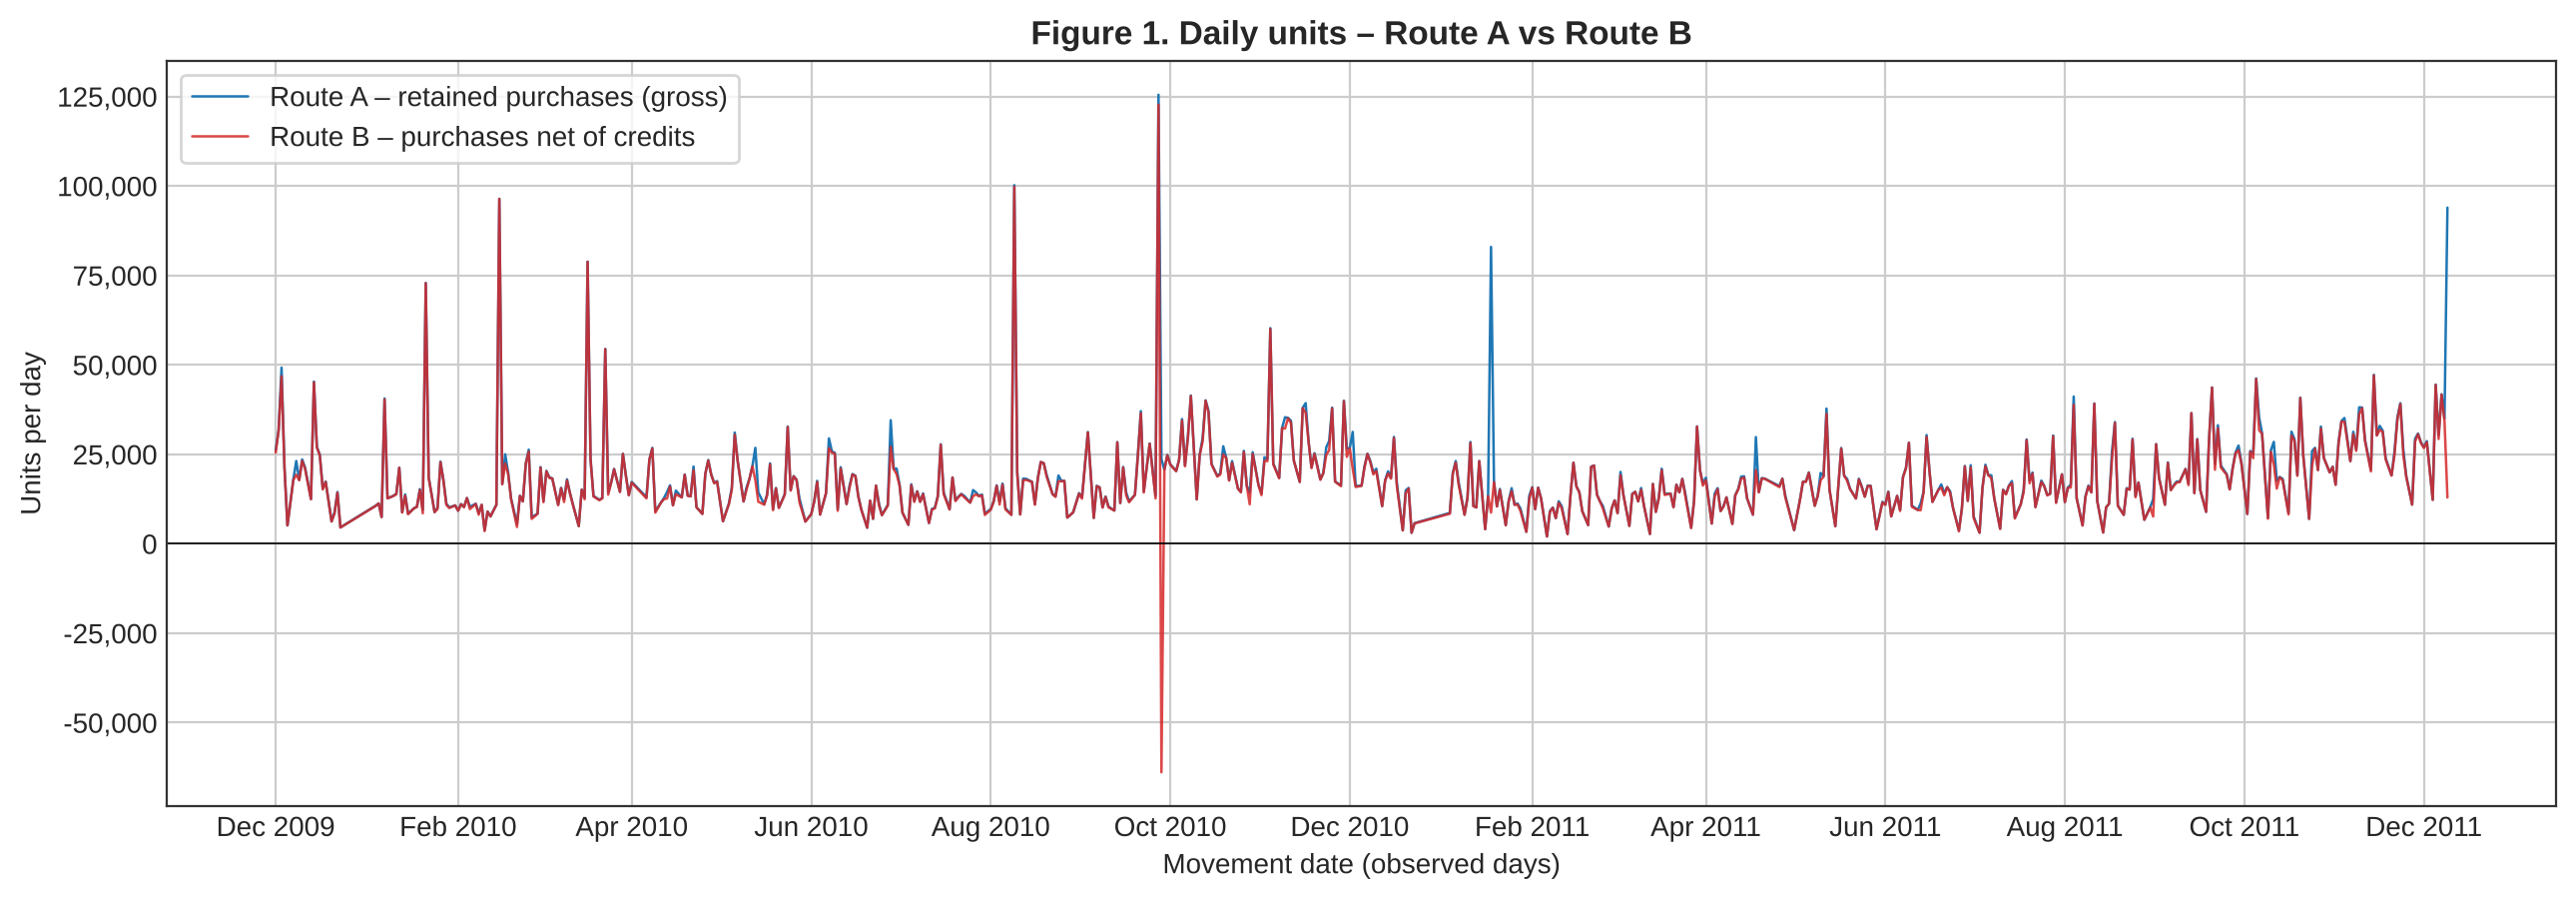

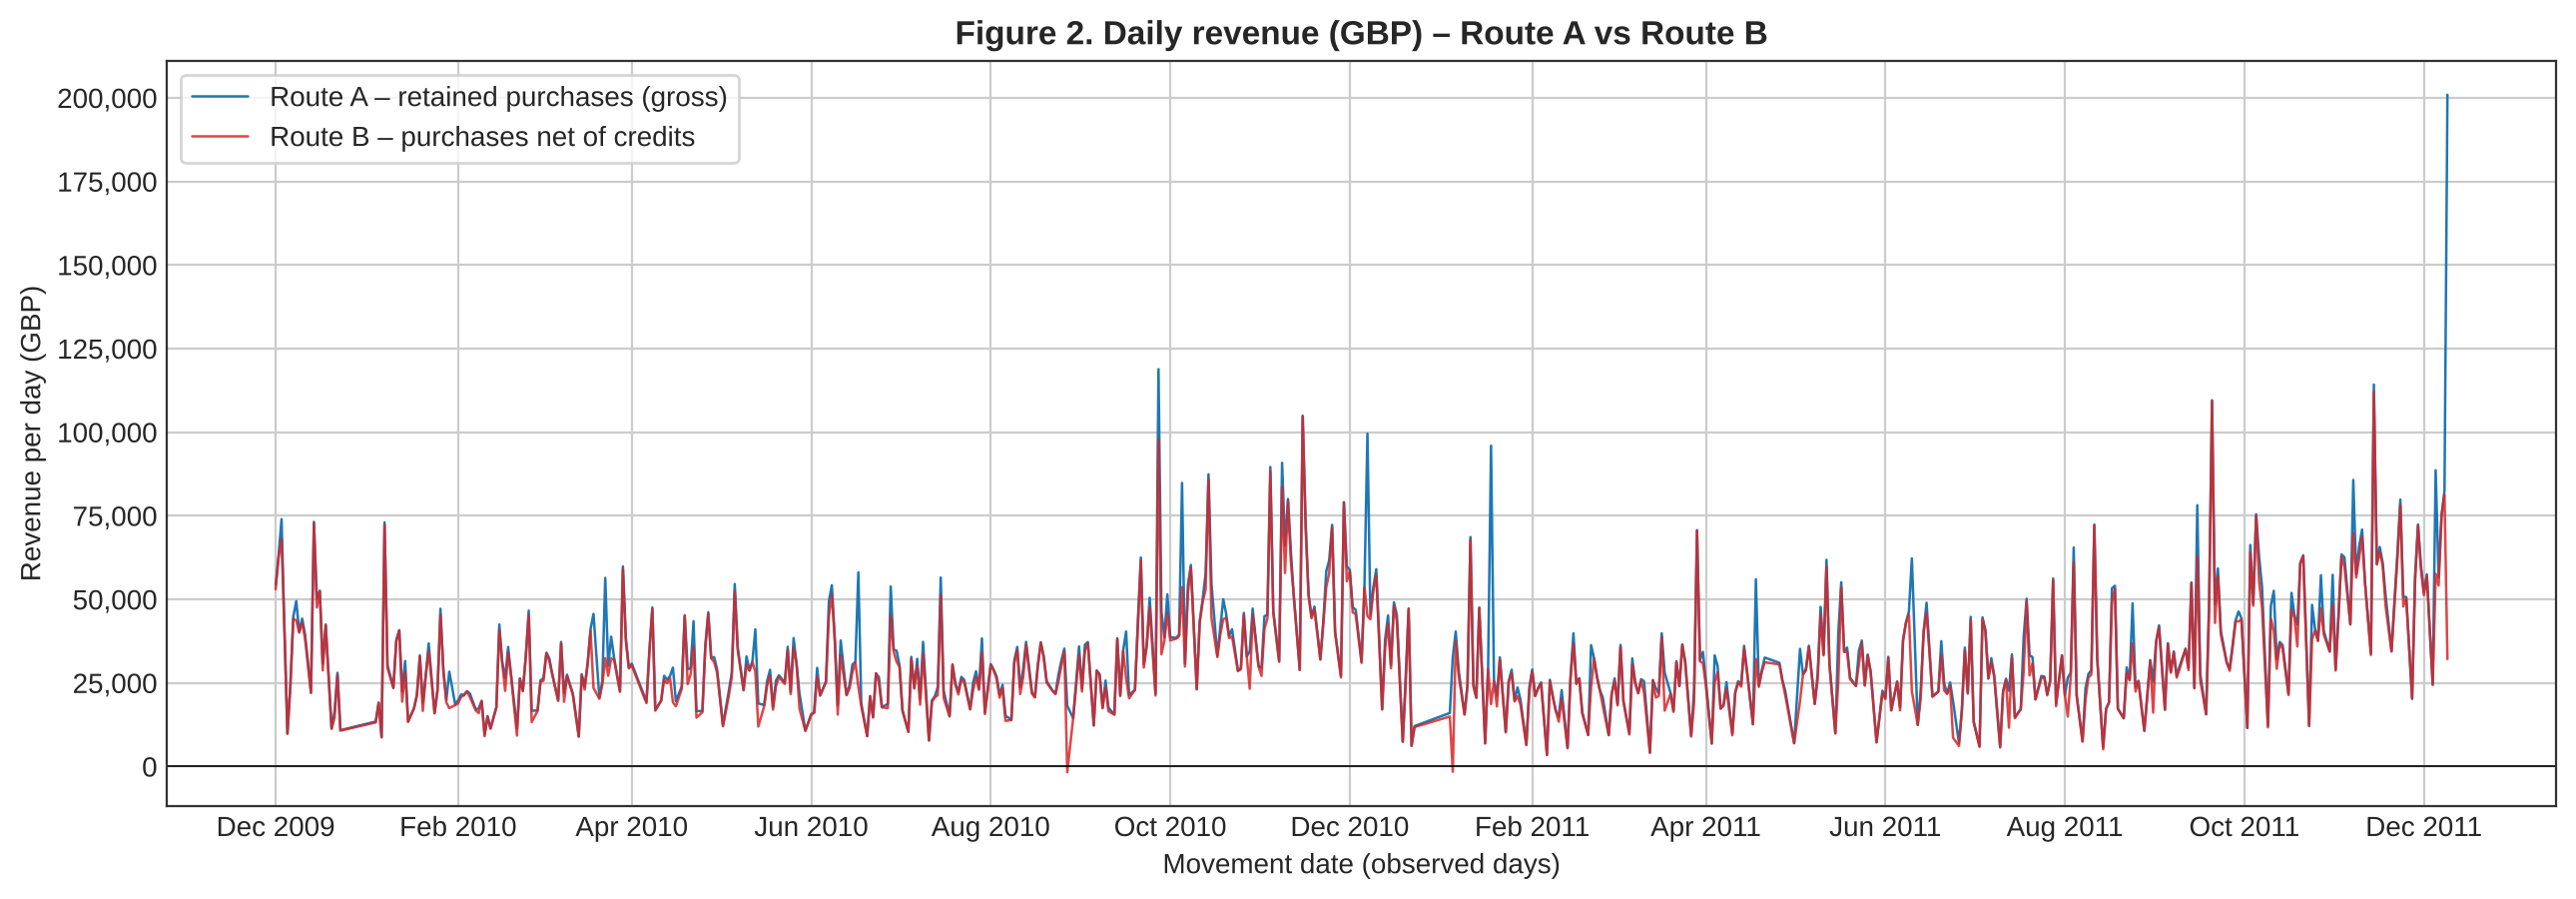

In [17]:
delta = pd.DataFrame({'dOrders': dB.TotalOrders - dA.TotalOrders, 'dUnits': dB.TotalUnits - dA.TotalUnits, 'dRevenue': dB.Revenue - dA.Revenue})
thousands = mticker.FuncFormatter(lambda x, p: f'{x:,.0f}')

def series(col, ylabel, title, filename):
    fig, ax = plt.subplots(figsize=(13, 4.6), dpi=200)
    ax.plot(dA.index, dA[col], color='#1f77b4', lw=0.9, label='Route A – retained purchases (gross)')
    ax.plot(dB.index, dB[col], color='#d62728', lw=0.9, alpha=0.85, label='Route B – purchases net of credits')
    ax.axhline(0, color='black', lw=0.6)
    ax.set_title(title, fontweight='bold'); ax.set_xlabel('Movement date (observed days)'); ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(thousands); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.legend(loc='upper left', frameon=True); fig.tight_layout(); fig.savefig(f'figures/{filename}', bbox_inches='tight'); plt.show()

series('TotalUnits', 'Units per day', 'Figure 1. Daily units – Route A vs Route B', 'fig1_daily_units.png')
series('Revenue', 'Revenue per day (GBP)', 'Figure 2. Daily revenue (GBP) – Route A vs Route B', 'fig2_daily_revenue.png')

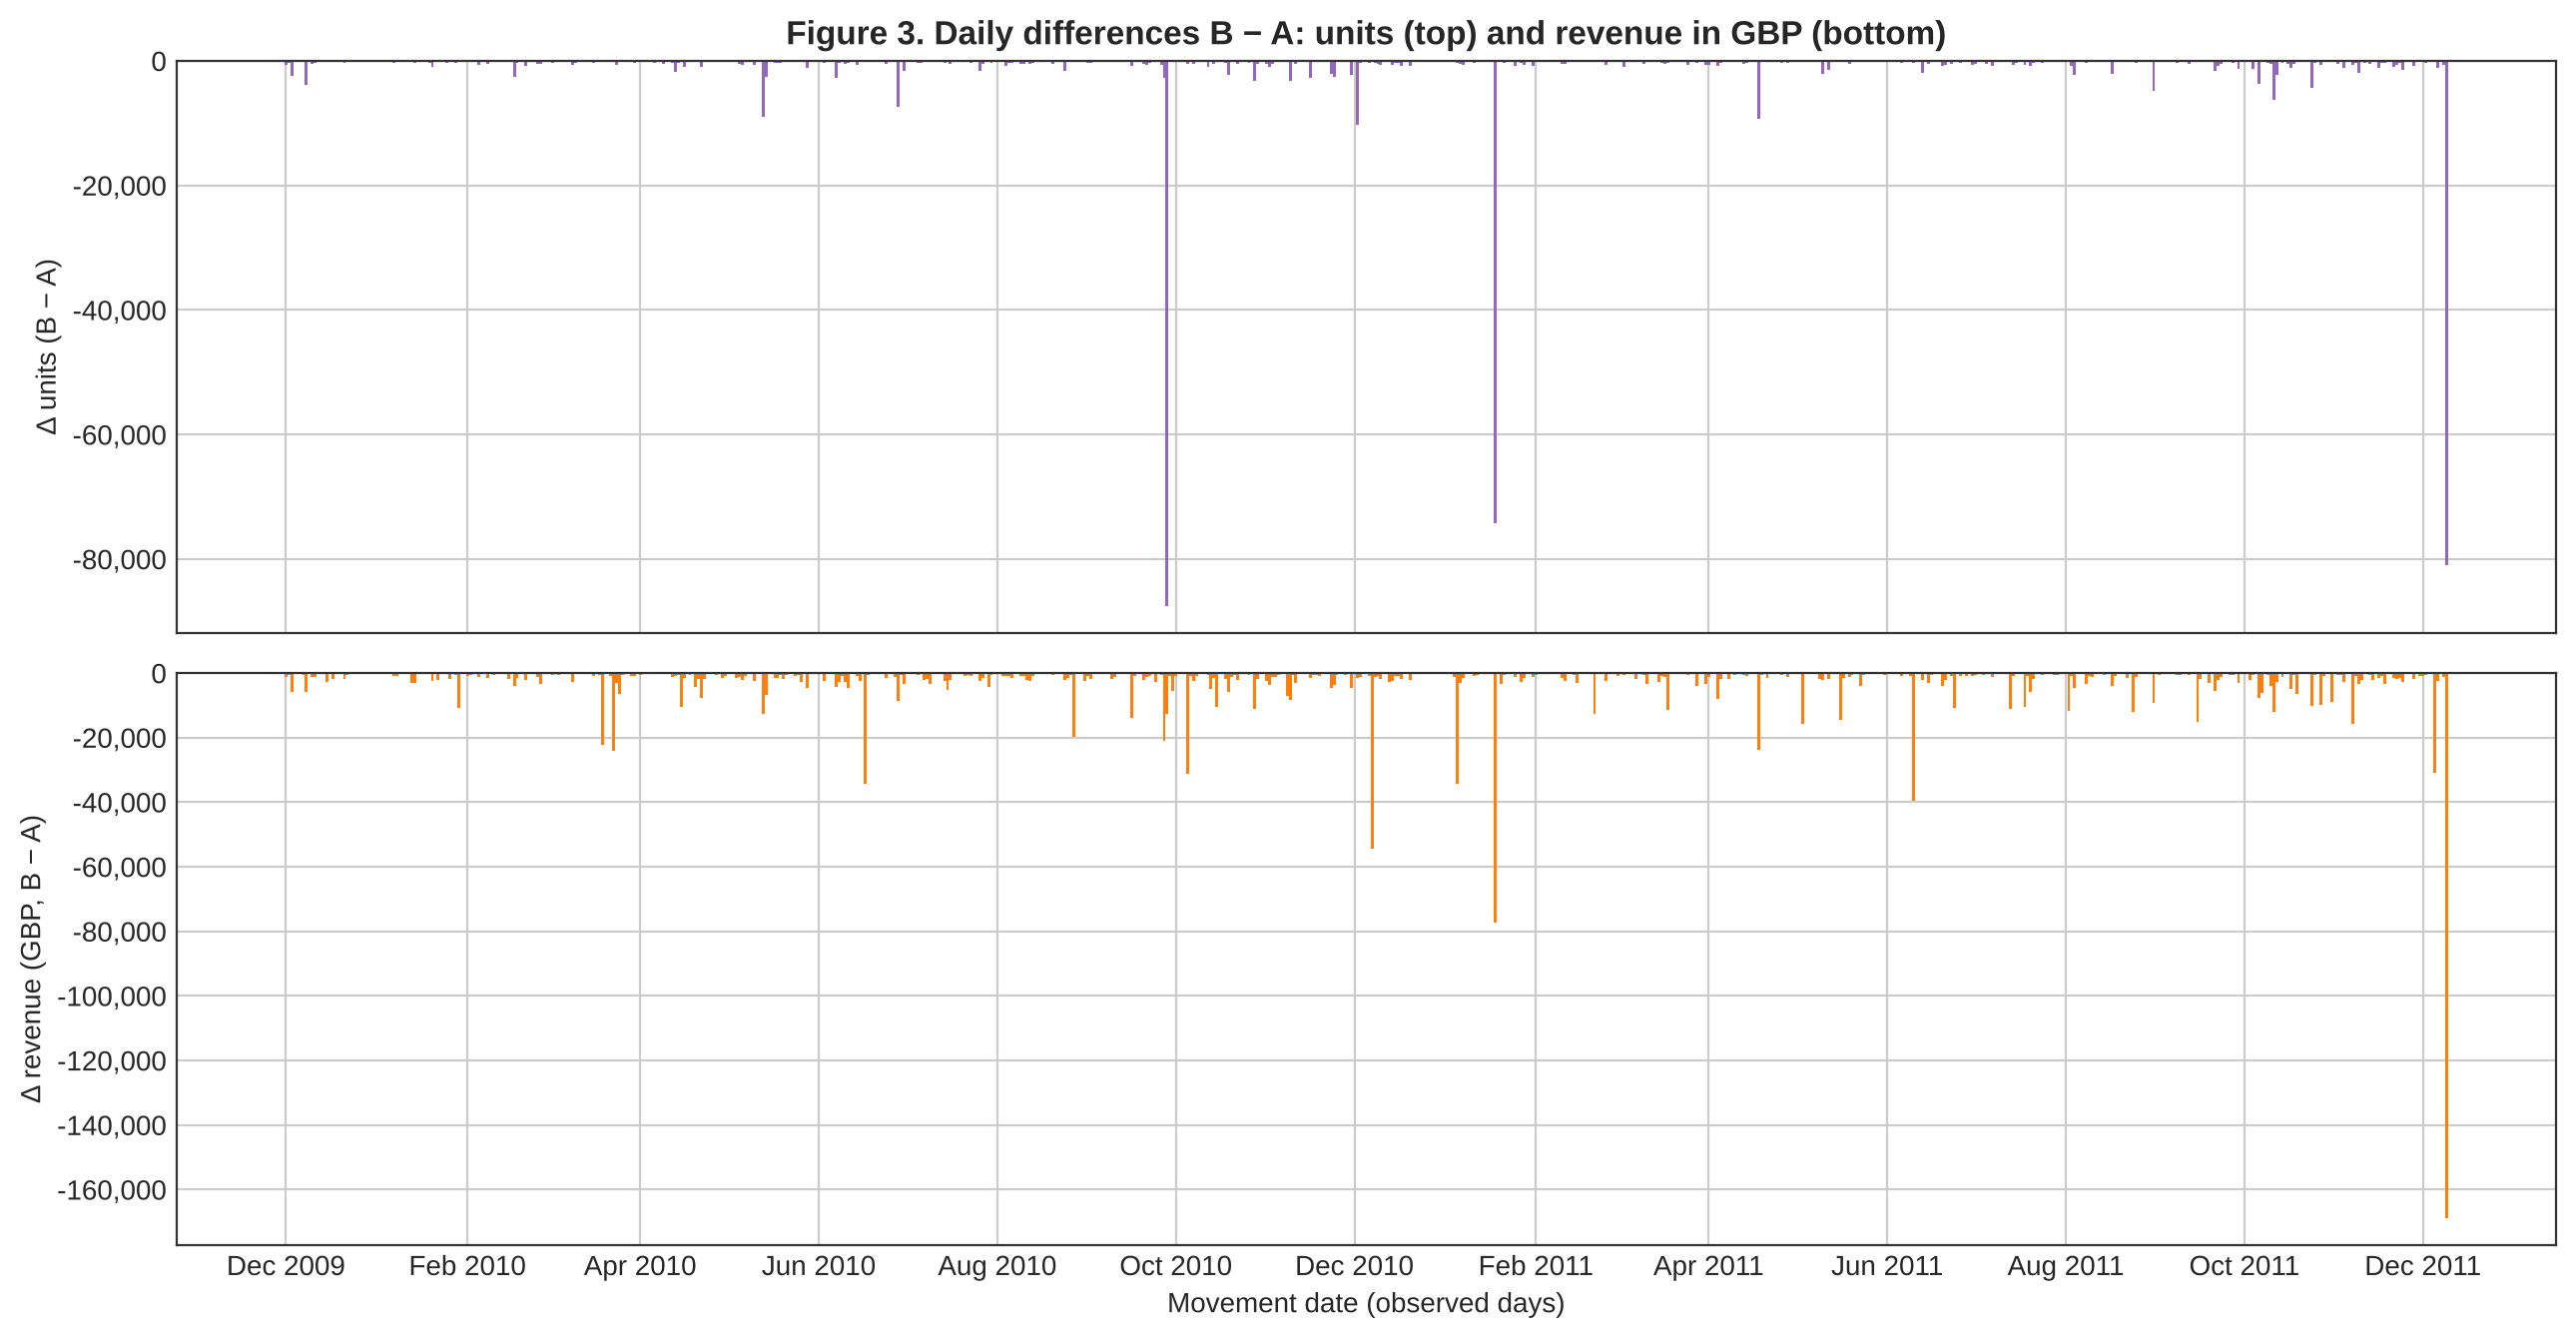

Days with Δ revenue ≠ 0: 598 of 604


In [18]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 6.8), dpi=200, sharex=True)
a1.bar(delta.index, delta.dUnits, width=1.0, color='#9467bd'); a1.set_ylabel('Δ units (B − A)'); a1.yaxis.set_major_formatter(thousands)
a1.set_title('Figure 3. Daily differences B − A: units (top) and revenue in GBP (bottom)', fontweight='bold')
a2.bar(delta.index, delta.dRevenue, width=1.0, color='#ff7f0e'); a2.set_ylabel('Δ revenue (GBP, B − A)'); a2.yaxis.set_major_formatter(thousands)
a2.set_xlabel('Movement date (observed days)'); a2.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); a2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
for a in (a1, a2): a.axhline(0, color='black', lw=0.6)
fig.tight_layout(); fig.savefig('figures/fig3_daily_differences.png', bbox_inches='tight'); plt.show()
print('Days with Δ revenue ≠ 0:', int((delta.dRevenue.round(6) != 0).sum()), 'of', len(delta))

In [19]:
def pct(b, a):
    return 'Not computable' if a == 0 else 100 * (b - a) / a
tot = pd.DataFrame({
    'A': [dA.TotalOrders.sum(), dA.TotalUnits.sum(), dA.Revenue.sum()],
    'B': [dB.TotalOrders.sum(), dB.TotalUnits.sum(), dB.Revenue.sum()]},
    index=['Summed daily orders', 'Units', 'Revenue in GBP'])
tot['Δ B−A'] = tot['B'] - tot['A']
tot['Δ % over A'] = [pct(b, a) for a, b in zip(tot['A'], tot['B'])]
display(tot)

# Check: B − A = sum of recognized credits
print('Δ revenue =', round(tot.loc['Revenue in GBP', 'Δ B−A'], 2), '| sum of credit LineAmount =', round(credits.LineAmount.sum(), 2))
print('Δ units =', int(tot.loc['Units', 'Δ B−A']), '| sum of credit Quantity =', int(credits.Quantity.sum()))
assert np.isclose(tot.loc['Revenue in GBP', 'Δ B−A'], credits.LineAmount.sum())
assert tot.loc['Units', 'Δ B−A'] == credits.Quantity.sum()
R['totales'] = {i: dict(A=float(tot.loc[i, 'A']), B=float(tot.loc[i, 'B']), d=float(tot.loc[i, 'Δ B−A']),
                        p=(None if isinstance(tot.loc[i, 'Δ % over A'], str) else float(tot.loc[i, 'Δ % over A']))) for i in tot.index}

,A,B,Δ B−A,Δ % over A
Summed daily orders,4.007700e+04,4.007700e+04,0.00,0.000000
Units,1.120515e+07,1.072833e+07,-476820.00,-4.255365
Revenue in GBP,2.047626e+07,1.901384e+07,-1462424.18,-7.142047


Δ revenue = -1462424.18 | sum of credit LineAmount = -1462424.18
Δ units = -476820 | sum of credit Quantity = -476820


### Three days with the largest absolute monetary difference and the credits behind them

In [20]:
top3 = delta.reindex(delta.dRevenue.abs().sort_values(ascending=False).index).head(3)
aud_idx = audit.set_index('SourceRow')
top3_rows = []
for day, r in top3.iterrows():
    cr = credits[credits.Date == day].sort_values('LineAmount')
    print(f"\n{day.date()}  ΔRevenue = £{r.dRevenue:,.2f}  ({pct(dB.loc[day,'Revenue'], dA.loc[day,'Revenue']):.2f}% over A = £{dA.loc[day,'Revenue']:,.2f})  | credits: {len(cr)} lines in {cr.Invoice.nunique()} C invoices")
    main = cr.head(3)[['SourceRow','Invoice','StockCode','Description','Quantity','Price','LineAmount','CustomerID','InvoiceDate']]
    display(main)
    display(aud_idx.loc[main.SourceRow, ['Status', 'LinkedInvoice', 'Reason']])
    print('Credits that day by StockCode:')
    display(cr.groupby('StockCode')['LineAmount'].agg(['size', 'sum']).sort_values('sum').head(4).round(2))
    share = 100 * cr.head(1).LineAmount.sum() / r.dRevenue
    top3_rows.append(dict(fecha=str(day.date()), d=float(r.dRevenue), p=float(pct(dB.loc[day,'Revenue'], dA.loc[day,'Revenue'])),
                          A=float(dA.loc[day,'Revenue']), B=float(dB.loc[day,'Revenue']), n_lineas=len(cr), n_fact=int(cr.Invoice.nunique()), share_top1=float(share),
                          principales=[dict(inv=x.Invoice, sc=x.StockCode, desc=str(x.Description), q=int(x.Quantity), p=float(x.Price), amt=float(x.LineAmount),
                                            cid=(None if pd.isna(x.CustomerID) else int(x.CustomerID)), hora=str(x.InvoiceDate),
                                            estado=aud_idx.loc[x.SourceRow, 'Status'], link=str(aud_idx.loc[x.SourceRow, 'LinkedInvoice'])) for x in main.itertuples()]))
R['top3'] = top3_rows


2011-12-09  ΔRevenue = £-168,789.07  (-84.01% over A = £200,918.98)  | credits: 7 lines in 5 C invoices


,SourceRow,Invoice,StockCode,Description,Quantity,Price,LineAmount,CustomerID,InvoiceDate
1065883,1065884,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60,16446,2011-12-09 09:27:00
1067002,1067003,C581499,M,Manual,-1,224.69,-224.69,15498,2011-12-09 10:28:00
1067176,1067177,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,10.95,-54.75,15311,2011-12-09 11:57:00


,Status,LinkedInvoice,Reason
SourceRow,,,
1065884,Reconciled,581483,Single earlier invoice with sufficient balance
1067003,Unreconciled,NaN,No earlier purchase of the product by the cust...
1067177,Ambiguous,NaN,Several candidate invoices


Credits that day by StockCode:


,size,sum
StockCode,,
23843,1,-168469.60
M,1,-224.69
21258,1,-54.75
22178,1,-23.40


...


2010-12-07  ΔRevenue = £-54,559.15  (-54.80% over A = £99,553.85)  | credits: 34 lines in 18 C invoices


,SourceRow,Invoice,StockCode,Description,Quantity,Price,LineAmount,CustomerID,InvoiceDate
519294,519295,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,<NA>,2010-12-07 15:49:00
517953,517954,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,<NA>,2010-12-07 15:04:00
519170,519171,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,-13474.79,<NA>,2010-12-07 15:34:00


,Status,LinkedInvoice,Reason
SourceRow,,,
519295,Unreconciled,NaN,No identified customer
517954,Unreconciled,NaN,No identified customer
519171,Unreconciled,NaN,No identified customer


Credits that day by StockCode:


,size,sum
StockCode,,
AMAZONFEE,6,-52784.41
M,2,-945.09
D,1,-281.00
21258,1,-131.40


In [21]:
# Same-day purchases of the product behind the largest credit (purchase change or credit-driven change?)
for t in top3_rows:
    p0 = t['principales'][0]
    same = purchases[(purchases.StockCode == p0['sc']) & (purchases.Date == pd.Timestamp(t['fecha']))]
    print(t['fecha'], p0['sc'], '- purchases of the same product that day:')
    display(same[['SourceRow','Invoice','Quantity','Price','LineAmount','CustomerID','InvoiceDate']])

2011-12-09 23843 - purchases of the same product that day:


,SourceRow,Invoice,Quantity,Price,LineAmount,CustomerID,InvoiceDate
1065882,1065883,581483,80995,2.08,168469.6,16446,2011-12-09 09:15:00


2011-01-18 23166 - purchases of the same product that day:


,SourceRow,Invoice,Quantity,Price,LineAmount,CustomerID,InvoiceDate
587080,587081,541431,74215,1.04,77183.6,12346,2011-01-18 10:01:00


2010-12-07 AMAZONFEE - purchases of the same product that day:


,SourceRow,Invoice,Quantity,Price,LineAmount,CustomerID,InvoiceDate
517955,517956,537632,1,13541.33,13541.33,<NA>,2010-12-07 15:08:00


### Monthly summary (context only; December 2009 and December 2011 are partial months)

In [22]:
mA = dA.groupby(month(dA)).agg(Orders=('TotalOrders', 'sum'), UnitsA=('TotalUnits', 'sum'), RevenueA=('Revenue', 'sum'), Days=('Revenue', 'size'))
mB = dB.groupby(month(dB)).agg(UnitsB=('TotalUnits', 'sum'), RevenueB=('Revenue', 'sum'))
monthly = mA.join(mB)
monthly['dRevenue'] = monthly.RevenueB - monthly.RevenueA
monthly['dRevenue_%'] = 100 * monthly['dRevenue'] / monthly.RevenueA
monthly['dUnits'] = monthly.UnitsB - monthly.UnitsA
monthly['MoM_A_%'] = 100 * monthly.RevenueA.pct_change()
monthly['MoM_B_%'] = 100 * monthly.RevenueB.pct_change()
monthly['Partial'] = ''
monthly.iloc[0, -1] = 'Partial'; monthly.iloc[-1, -1] = 'Partial'
display(monthly.round(2))
R['mensual'] = {str(k): {c: (v if isinstance(v, str) else float(v)) for c, v in row.items()} for k, row in monthly.iterrows()}

,Orders,UnitsA,RevenueA,Days,UnitsB,RevenueB,dRevenue,dRevenue_%,dUnits,MoM_A_%,MoM_B_%,Partial
Date,,,,,,,,,,,,
2009-12,1682,425461,822483.95,21,415445,796648.50,-25835.45,-3.14,-10016,NaN,NaN,Partial
2010-01,1105,390672,651155.11,24,386792,622479.50,-28675.61,-4.40,-3880,-20.83,-21.86,
2010-02,1201,381879,551504.73,24,374927,530891.80,-20612.93,-3.74,-6952,-15.30,-14.71,
2010-03,1681,526026,830915.26,27,521549,763247.24,-67668.02,-8.14,-4477,50.66,43.77,
2010-04,1462,366705,678875.25,23,360222,641521.05,-37354.20,-5.50,-6483,-18.30,-15.95,
2010-05,1500,395868,657705.50,24,379269,613270.72,-44434.78,-6.76,-16599,-3.12,-4.40,
2010-06,1645,406820,749537.31,26,391338,677073.87,-72463.44,-9.67,-15482,13.96,10.40,
2010-07,1529,337895,648810.27,26,331710,617365.48,-31444.79,-4.85,-6185,-13.44,-8.82,
2010-08,1425,472380,695251.91,26,465691,654774.39,-40477.52,-5.82,-6689,7.16,6.06,


### Additional risks found in the retained purchases (apply to both routes)
The activity rules define every non-`C` line with positive quantity and price as a valid purchase; this includes
movements that are not merchandise. They are quantified for reporting without changing the rules.

In [23]:
non_merch = ['POST', 'DOT', 'M', 'C2', 'BANK CHARGES', 'AMAZONFEE', 'ADJUST', 'ADJUST2', 'D', 'S', 'B', 'CRUK', 'PADS', 'TEST001', 'TEST002', 'gift_0001_10', 'gift_0001_20', 'gift_0001_30', 'gift_0001_40', 'gift_0001_50', 'SP1002']
nm = purchases[purchases.StockCode.str.upper().isin([s.upper() for s in non_merch])]
display(nm.groupby('StockCode').agg(Lines=('SourceRow', 'size'), Amount=('LineAmount', 'sum')).sort_values('Amount', ascending=False).round(2))
adjust = purchases[purchases.Invoice.str.startswith('A')]
display(adjust[['SourceRow','Invoice','StockCode','Description','Quantity','Price','InvoiceDate']])
R['riesgos'] = dict(no_merc_lineas=int(len(nm)), no_merc_importe=float(nm.LineAmount.sum()), pct_no_merc=float(100 * nm.LineAmount.sum() / purchases.LineAmount.sum()),
                    ajuste_A=adjust[['Invoice','StockCode','Description','Price','InvoiceDate']].astype(str).to_dict('records'),
                    sin_cliente_compras=int(purchases.CustomerID.isna().sum()), sin_cliente_importe=float(purchases[purchases.CustomerID.isna()].LineAmount.sum()),
                    abonos_sin_cliente_importe=float(credits[credits.CustomerID.isna()].LineAmount.sum()),
                    abonos_M=float(credits[credits.StockCode == 'M'].LineAmount.sum()))
print(R['riesgos'])

,Lines,Amount
StockCode,,
M,846,339226.24
DOT,1415,309854.11
POST,1851,125682.42
AMAZONFEE,3,20467.80
C2,267,13426.00
B,1,11062.06
ADJUST,36,8897.93
ADJUST2,3,731.05
gift_0001_30,24,610.09


,SourceRow,Invoice,StockCode,Description,Quantity,Price,InvoiceDate
825443,825444,A563185,B,Adjust bad debt,1,11062.06,2011-08-12 14:50:00


{'no_merc_lineas': 4573, 'no_merc_importe': 832284.448, 'pct_no_merc': 4.064631088833863, 'ajuste_A': [{'Invoice': 'A563185', 'StockCode': 'B', 'Description': 'Adjust bad debt', 'Price': '11062.06', 'InvoiceDate': '2011-08-12 14:50:00'}], 'sin_cliente_compras': 228488, 'sin_cliente_importe': 3101456.1799999997, 'abonos_sin_cliente_importe': -377611.2, 'abonos_M': -422926.13999999996}


### Share of the credited amount by traceability
Reconciliation describes traceability, not recognition: every documented `C` credit is recognized in B. Here we
quantify how much of the credited amount has a link under the rule.

In [24]:
audit['Amount'] = -audit['ReturnedUnits'] * audit['Price']
trace = audit.groupby('Status')['Amount'].sum().reindex(ORDER)
trace_pct = 100 * trace / audit['Amount'].sum()
display(pd.DataFrame({'Credited amount GBP': trace.round(2), '% of total credited': trace_pct.round(2)}))
R['trazabilidad'] = {s: dict(importe=float(trace[s]), pct=float(trace_pct[s])) for s in ORDER}
R['trazabilidad']['pct_credito_sobre_A'] = float(100 * credits.LineAmount.sum() / purchases.LineAmount.sum())

# Merchandise credits vs service/adjustment codes (M, AMAZONFEE, BANK CHARGES, POST, D, ...)
service_codes = [s.upper() for s in non_merch]
audit['Type'] = np.where(audit['StockCode'].str.upper().isin(service_codes), 'Service/adjustment', 'Merchandise')
pv = audit.pivot_table(index='Type', columns='Status', values='Amount', aggfunc='sum').reindex(columns=ORDER).fillna(0)
pv['Total'] = pv.sum(axis=1)
pv_pct = 100 * pv[ORDER].div(pv['Total'], axis=0)
display(pv.round(2)); display(pv_pct.round(2))
print('Credits without customer by StockCode (amount):')
display(audit[audit.CustomerID.isna()].groupby('StockCode')['Amount'].agg(['size', 'sum']).sort_values('sum', ascending=False).head(6).round(2))
R['trazabilidad']['por_tipo'] = {t: {c: float(pv.loc[t, c]) for c in pv.columns} for t in pv.index}
R['trazabilidad']['por_tipo_pct'] = {t: {c: float(pv_pct.loc[t, c]) for c in ORDER} for t in pv_pct.index}
R['trazabilidad']['no_conc_por_motivo'] = audit[audit.Status == 'Unreconciled'].groupby('Reason')['Amount'].sum().to_dict()

,Credited amount GBP,% of total credited
Status,,
Reconciled,-588174.90,40.22
Ambiguous,-132723.50,9.08
Unreconciled,-741525.78,50.71


Status,Reconciled,Ambiguous,Unreconciled,Total
Type,,,,
Merchandise,-529604.79,-121199.3,-65691.44,-716495.53
Service/adjustment,-58570.11,-11524.2,-675834.34,-745928.65


Status,Reconciled,Ambiguous,Unreconciled
Type,,,
Merchandise,73.92,16.92,9.17
Service/adjustment,7.85,1.54,90.60


Credits without customer by StockCode (amount):


,size,sum
StockCode,,
17003,1,-0.42
21703,1,-0.42
85172,1,-0.42
82580,1,-0.55
21902,1,-0.65
22436,1,-0.65


---
## Decision and export of the selected route
**Selected route: B (purchases net of recorded credits).** Rationale (detailed in the report):
1. `C` credits are explicit commercial documents with a positive price; leaving them out (Route A) overstates revenue and
   units by exactly the credited amount.
2. B does not alter orders or purchases: the B − A difference matches the sum of recognized credits to the penny.
3. Credits are recorded on their own date, without rewriting history, which allows RFM and repurchase datasets to be
   built without information leakage.

**Reported limitation:** only part of the credited amount has an identified originating invoice under the rule; the
rest (ambiguous or unreconciled) is recognized because it is documented, but its link to a purchase cannot be traced
with the available data. `Revenue` is **not** profit (no costs are available).

In [25]:
ROUTE = 'B'
sel = routeB if ROUTE == 'B' else purchases
tp = sel[['SourceRow', 'Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country', 'LineAmount', 'Date', 'MovementType']].sort_values('SourceRow').copy()
tp['InvoiceDate'] = tp['InvoiceDate'].dt.strftime('%Y-%m-%d %H:%M:%S')
tp['Date'] = tp['Date'].dt.strftime('%Y-%m-%d')
tp.to_csv('outputs/transacciones_procesadas.csv', index=False)
exportable(dB if ROUTE == 'B' else dA).to_csv('outputs/indicadores_diarios.csv', index=False)

# Exclusion log with reasons (traceability complement)
log = df[['SourceRow', 'Invoice', 'CommonExclusion']].dropna(subset=['CommonExclusion']).rename(columns={'CommonExclusion': 'Reason'})
log['Stage'] = 'Common'
la = base.loc[base.RouteA_Status != 'Valid purchase', ['SourceRow', 'Invoice', 'RouteA_Status']].rename(columns={'RouteA_Status': 'Reason'}); la['Stage'] = 'Route A'
lb = base.loc[~base.RouteB_Status.isin(['Valid purchase', 'Recognized C credit']), ['SourceRow', 'Invoice', 'RouteB_Status']].rename(columns={'RouteB_Status': 'Reason'}); lb['Stage'] = 'Route B'
exclusion_log = pd.concat([log, la, lb])[['SourceRow', 'Stage', 'Invoice', 'Reason']].sort_values(['Stage', 'SourceRow'])
exclusion_log.to_csv('outputs/registro_exclusiones.csv', index=False)
display(exclusion_log.groupby(['Stage', 'Reason']).size().rename('Lines').to_frame())

# Reconstruction check from the original
chk = pd.read_csv('outputs/transacciones_procesadas.csv', dtype={'Invoice': str, 'StockCode': str})
assert len(chk) == nB_keep and chk.SourceRow.is_unique
assert chk.CustomerID.isna().sum() == sel.CustomerID.isna().sum()
assert set(chk.MovementType) == {'Purchase', 'Credit'}
print('transacciones_procesadas.csv:', chk.shape, chk.MovementType.value_counts().to_dict())
print('Common base = Route B kept + Route B excluded (log):', nB_keep + int((exclusion_log.Stage == 'Route B').sum()), '=', N_BASE)
R['export'] = dict(ruta=ROUTE, filas_tp=len(chk), cols=list(chk.columns), mov=chk.MovementType.value_counts().to_dict(), registro=len(exclusion_log))
with open('outputs/resultados_informe.json', 'w', encoding='utf-8') as fh:
    json.dump(R, fh, ensure_ascii=False, indent=1, default=str)
chk.head()

Lines
Stage   Reason                                  
Common  Exact duplicate (additional copy)  34335
Route A C prefix                           19104
        Price <= 0                          2626
        Quantity <= 0                       3393
Route B C exception (Q>=0 or P<=0)             1
        Negative without C                  3393
        Non-positive price without C        2626

transacciones_procesadas.csv: (1027016, 12) {'Purchase': 1007913, 'Credit': 19103}
Common base = Route B kept + Route B excluded (log): 1033036 = 1033036


,SourceRow,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,LineAmount,Date,MovementType
0,1,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12-01,Purchase
1,2,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01,Purchase
2,3,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01,Purchase
3,4,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12-01,Purchase
4,5,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12-01,Purchase


### Generated files
File names follow the assignment specification.

| File | Content |
|---|---|
| `outputs/transacciones_procesadas.csv` | Route B: 8 original columns (`Customer ID` → `CustomerID`), `SourceRow`, `LineAmount`, `Date`, `MovementType` (Purchase/Credit) |
| `outputs/indicadores_diarios.csv` | Route B: `Date` (YYYY-MM-DD), `TotalOrders`, `TotalUnits`, `Revenue` |
| `outputs/indicadores_diarios_comparacion.csv` | Both routes with a `Route` column |
| `outputs/auditoria_conciliacion_abonos.csv` | Complement: one row per C credit with candidates, link, status and reason |
| `outputs/registro_exclusiones.csv` | Complement: excluded `SourceRow` by stage and reason |
| `outputs/resultados_informe.json` | Figures used in the report |